# OCR DETECTION (NUXIA PROJECT):

## 1. Import libraries and dependancies

In [ ]:
#pip install paddleocr
#pip install paddlepaddle


In [5]:
from paddleocr import PaddleOCR
import matplotlib.pyplot as plt
from pathlib import Path
import cv2
import numpy as np
import shutil
import json
import re
from datetime import datetime
from datetime import date
from difflib import SequenceMatcher



### Data Structure:

/main 


//pruebas,//pruebas,//pruebas

//data_train (entrenar el classifier)
//data_all (divididas en troqueladas y no con sus previos análisis)

## 2. Classification model for die cut images

### 2.1. Pipeline to obtain the data to train the classifier

In [ ]:
# DO NOT RUN

path = #

In [ ]:
# DO NOT RUN

CARPETA_ORIGEN = path / "pruebas14082026"
CARPETA_DESTINO = path / "data_train"
EXTENSIONES = {".png", ".jpg", ".jpeg"}

CARPETA_DESTINO.mkdir(exist_ok=True)

copiadas = 0
sin_original = []

for subcarpeta in sorted(p for p in CARPETA_ORIGEN.iterdir() if p.is_dir()):
    candidatas = [
        f for f in subcarpeta.iterdir()
        if f.stem.lower() == "original" and f.suffix.lower() in EXTENSIONES
    ]

    if not candidatas:
        sin_original.append(subcarpeta.name)
        continue

    origen = candidatas[0]
    destino_dir = CARPETA_DESTINO / subcarpeta.name
    destino_dir.mkdir(exist_ok=True)

    # copia la imagen (el original queda intacto)
    shutil.copy2(origen, destino_dir / f"original{origen.suffix.lower()}")

    # crea el txt vacío para etiquetar, sin pisar uno que ya hayas rellenado
    etiqueta = destino_dir / "etiqueta.txt"
    if not etiqueta.exists():
        etiqueta.touch()

    copiadas += 1


### 2.2 Train the classifier

In [ ]:
#

### Once we have the final images let's work with them

## 3. Image Preprocessing

In [6]:
paddle_ocr = PaddleOCR(
    lang="es",
    use_angle_cls=True,
    enable_mkldnn=False,                          # idioma (o "en", "ch", etc.)
    use_doc_orientation_classify=False, # desactiva módulos extra para ir más rápido
    use_doc_unwarping=False
)

C:\Users\sampe\AppData\Local\Temp\ipykernel_28296\401327702.py:1: DeprecationWarning: The parameter `use_angle_cls` has been deprecated and will be removed in the future. Please use `use_textline_orientation` instead.
  paddle_ocr = PaddleOCR(
c:\Users\sampe\anaconda3\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\sampe\.paddlex\official_models\PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\sampe\.paddlex\official_models\PP-OCRv6

In [ ]:
# Imágenes para utilizar (Copiar y pegar) en path_img = Path("pruebas14082026/1b4df212")

# 1a0b72b0 (Diferente formato) - Tiene que extraer todo
# 1a3b95bb (Troquelada) - No se extrae nada
# 1aaa2407 (Diferente formato) - Tiene que extraer todo
# 1b4df212 (Diferente formato) - Tiene que extraer todo
# 2b733ecd (Diferente formato) - Tiene que extraer todo
# 2c9787d9 (Diferente formato) - Tiene que extraer todo
# 4d95d836 (Diferente formato) - Tiene que extraer todo

In [ ]:
# Problemas:

# 1a0b72b0 - Junta dos líneas de texto
# 1a3b95bb
# 1aaa2407 - Lote: en Lote1 y vcto: en uct01. Los dos puntos los convierte en un 1
# 1b4df212 - Está rotada y no entiende bien el número de lote
# 2b733ecd - Junta dos líneas de texto
# 2c9787d9 - "Lote N° :"
# 4d95d836 - LOTE:, y FP Y FE

# ¿Cómo lidiar con rotadas? use_angle_cls=True
# Junta dos cadenas de texto (arriba y abajo en una)
# Convierte dos puntos en "1"

In [40]:
path_img = Path("pruebas14082026/2c9787d9") #Cambiar si trabajamos con otra carpeta

In [30]:
img = cv2.imread(str(path_img / "original.png"))

In [31]:
resultado = paddle_ocr.predict(img)

for res in resultado:
    #res.print()                      # muestra todo en consola
    res.save_to_img(str(path_img / "ocr_no_pre.png"))        # imagen con las cajas dibujadas
    res.save_to_json(str(path_img / "report.json"))     # JSON con textos y coordenadas

Extraer el texto

In [50]:
ruta_json = path_img / "report.json"

with open(ruta_json, "r", encoding="utf-8") as f:
    report = json.load(f)

rec_texts = report["rec_texts"]

# No modificar ni normalizar el texto original
texto = [str(text) for text in rec_texts]

# Unir los textos para buscar etiquetas o fechas
texto = "\n".join(texto)

print(texto)

Lote N° : FD250359
Fecha de Fab.: 01/2025
Fecha de Exp.: 12/2026


Función Maestra:

In [7]:
def funcion_maestra(texto):

    resultado = {
        "lote": None,
        "fecha_fabricacion": None,
        "fecha_caducidad": None
    }

    # ------------------------------------------------------------------
    # Configuración: para otros idiomas o medicamentos, amplía estos conjuntos
    # (en mayúsculas, sin espacios ni símbolos, y con O en lugar de 0)
    # ------------------------------------------------------------------
    ETIQ_LOTE = ["LOT", "LOTE", "BATCH", "LOTNO", "LOTNR"]
    ETIQ_FAB = ["MANUF", "MANUFACTURED", "MFG", "MFD", "MAN", "FAB", "FABRICACION", "PROD"]
    ETIQ_CAD = ["EXP", "EXF", "EXPIRY", "EXPIRES", "CAD", "CADUCIDAD", "USEBY"]

    patron_valor = re.compile(r"[A-Z0-9][A-Z0-9./_-]*", re.IGNORECASE)
    patron_pegado = re.compile(r"^(?:LOTE|LOT|BATCH)[.\-/]?([A-Z0-9][A-Z0-9./_-]*)$", re.IGNORECASE)

    patron_fecha = re.compile(
        r"(?<![\d/.\-])(?:"
        r"(?P<y5>\d{4})[/.\-](?P<m5>\d{1,2})[/.\-](?P<d5>\d{1,2})"         # aaaa/mm/dd
        r"|(?P<d>\d{1,2})[/.\-](?P<m1>\d{1,2})[/.\-](?P<y1>\d{4}|\d{2})"   # dd/mm/aaaa o dd/mm/aa
        r"|(?P<y2>\d{4})[/.\-](?P<m2>\d{1,2})"                              # aaaa-mm
        r"|(?P<m3>\d{1,2})[/.\-](?P<y3>\d{4})"                              # mm/aaaa
        r"|(?<![A-Za-z])(?P<m6>\d{1,2})/(?P<y6>\d{2})"                      # mm/aa (solo con "/")
        r"|(?P<m4>\d{1,2}) (?P<y4>\d{4})"                                   # mm aaaa
        r")(?![\d/.\-])"
    )

    # ------------------------------------------------------------------
    # 1. LOTE
    # ------------------------------------------------------------------
    lineas = [l.strip() for l in texto.splitlines() if l.strip()]

    # Para cada línea se guarda una lista de tokens con sus características:
    # (texto, es_etiqueta_lote, es_valor_lote, valor_pegado_a_etiqueta)
    info_lineas = []
    for linea in lineas:
        partes = re.split(r"[\s:：#=;,]+", linea)
        toks = [p.strip(" .°º") for p in partes if p.strip(" .°º")]

        info = []
        for t in toks:
            # ¿Es una etiqueta de lote (aproximada)?
            norm_t = re.sub(r"[^A-Z0-9]", "", t.upper()).replace("0", "O")
            sim_t = 0.0
            if norm_t:
                sim_t = max(SequenceMatcher(None, norm_t, e).ratio() for e in ETIQ_LOTE)
            es_etiqueta = sim_t >= 0.8

            # ¿Es un valor de lote válido? Se evalúa el token y, si la etiqueta
            # viene pegada al valor (LOT123), también el valor pegado.
            m_pegado = patron_pegado.match(t)
            pegado = m_pegado.group(1) if m_pegado else None

            flags = []
            for c in (t, pegado):
                if c is None:
                    flags.append(False)
                    continue
                norm_c = re.sub(r"[^A-Z0-9]", "", c.upper()).replace("0", "O")
                sim_c = 0.0
                if norm_c:
                    sim_c = max(SequenceMatcher(None, norm_c, e).ratio() for e in ETIQ_LOTE)
                flags.append(
                    patron_valor.fullmatch(c) is not None
                    and len(c) >= 3
                    and any(ch.isdigit() for ch in c)
                    and patron_fecha.fullmatch(c) is None
                    and sim_c < 0.8
                )
            es_valor, pegado_valido = flags

            info.append((t, es_etiqueta, es_valor, pegado if pegado_valido else None))
        info_lineas.append(info)

    lote = None
    for i, info in enumerate(info_lineas):
        for k, (t, es_etiqueta, es_valor, pegado) in enumerate(info):
            # Etiqueta pegada al valor: LOT123, LOTE-ABC12, BATCH.5567
            if pegado:
                lote = pegado
                break

            if not es_etiqueta:
                continue

            # Candidatos por orden de prioridad:
            # a) mismo renglón: después de la etiqueta y luego antes
            # b) líneas siguientes (hasta 3)
            # c) líneas anteriores (hasta 2), valor impreso antes de la etiqueta
            candidatos = [x[0] for x in info[k + 1:] if x[2]]
            candidatos += [x[0] for x in info[:k][::-1] if x[2]]
            for j in range(i + 1, min(i + 4, len(info_lineas))):
                candidatos += [x[0] for x in info_lineas[j] if x[2]]
            for j in range(i - 1, max(i - 3, -1), -1):
                candidatos += [x[0] for x in info_lineas[j] if x[2]]

            if candidatos:
                lote = candidatos[0]
                break

            # Plan B: no hay etiqueta, se busca un código que parezca un lote
    if lote is None:
        patron_unidad = re.compile(
            r"^\d+([.,]\d+)?(MG|ML|G|MCG|UG|UI|IU|KG|L|MM|CM)$", re.IGNORECASE
        )
        for info in info_lineas:
            for t, es_etiqueta, es_valor, pegado in info:
                if (
                    es_valor                                  # alfanumérico, con dígito, no es fecha ni etiqueta
                    and len(t) >= 4
                    and any(c.isalpha() for c in t)           # mezcla letras y números
                    and not patron_unidad.match(t)            # descarta dosis: 500MG, 10ML...
                ):
                    lote = t
                    break
            if lote:
                break

    resultado["lote"] = lote

    # ------------------------------------------------------------------
    # 2. FECHAS
    # ------------------------------------------------------------------
    fechas = []  # (año, mes, inicio, fin)
    for m in patron_fecha.finditer(texto):
        g = m.groupdict()
        if g["y5"]:
            mes, anio = int(g["m5"]), g["y5"]
        elif g["d"]:
            mes, anio = int(g["m1"]), g["y1"]
        elif g["y2"]:
            mes, anio = int(g["m2"]), g["y2"]
        elif g["m3"]:
            mes, anio = int(g["m3"]), g["y3"]
        elif g["m6"]:
            mes, anio = int(g["m6"]), g["y6"]
        else:
            mes, anio = int(g["m4"]), g["y4"]

        anio = int(anio) + (2000 if len(anio) == 2 else 0)
        if 1 <= mes <= 12 and 2000 <= anio <= 2100:
            fechas.append((anio, mes, m.start(), m.end()))

    unicas = sorted({(a, mes) for a, mes, _, _ in fechas})
    fab = cad = None

    if len(unicas) >= 2:
        # El orden cronológico no depende de lo bien que el OCR lea las etiquetas
        fab, cad = unicas[0], unicas[-1]

    elif len(unicas) == 1:
        a, mes, ini, fin = fechas[0]
        tipo = None

        # Palabras cercanas: primero las anteriores a la fecha, luego las posteriores
        antes = re.findall(r"[A-Za-z0-9]+", texto[max(0, ini - 25):ini])[-2:]
        despues = re.findall(r"[A-Za-z0-9]+", texto[fin:fin + 25])[:2]
        for palabra in list(reversed(antes)) + despues:
            if palabra.isdigit():
                continue
            norm_p = re.sub(r"[^A-Z0-9]", "", palabra.upper()).replace("0", "O")
            if not norm_p:
                continue
            sc_cad = max(SequenceMatcher(None, norm_p, e).ratio() for e in ETIQ_CAD)
            sc_fab = max(SequenceMatcher(None, norm_p, e).ratio() for e in ETIQ_FAB)
            if max(sc_cad, sc_fab) >= 0.5:
                tipo = "cad" if sc_cad >= sc_fab else "fab"
                break

        # Sin etiqueta fiable: si es futura se asume caducidad, si no, fabricación
        if tipo is None:
            hoy = date.today()
            tipo = "cad" if (a, mes) >= (hoy.year, hoy.month) else "fab"

        if tipo == "cad":
            cad = (a, mes)
        else:
            fab = (a, mes)

    resultado["fecha_fabricacion"] = f"{fab[0]}-{fab[1]:02d}" if fab else None
    resultado["fecha_caducidad"] = f"{cad[0]}-{cad[1]:02d}" if cad else None

    return resultado


Ejemplo:

In [54]:
# Ejemplo de uso
datos = funcion_maestra(texto)

print(json.dumps(datos, indent=4, ensure_ascii=False))

{
    "texto_original": "Lote N° : FD250359\nFecha de Fab.: 01/2025\nFecha de Exp.: 12/2026",
    "lote": "FD250359",
    "fecha_produccion": "01/2025",
    "fecha_caducidad": "12/2026"
}


### Vamos a probar con una selección de 15 imágenes, para ello definimos una función

In [8]:
def process_image(ocr, img):
    
    # 1. Ejecutar el OCR sobre la imagen
    prediccion = ocr.predict(img)

    # 2. Extraer los textos reconocidos
    rec_texts = []

    for pagina in prediccion:
        datos = pagina.json if hasattr(pagina, "json") else pagina

        # Algunas versiones de PaddleOCR devuelven un método json()
        if callable(datos):
            datos = datos()

        if isinstance(datos, str):
            datos = json.loads(datos)

        if isinstance(datos, dict):
            datos = datos.get("res", datos)
            rec_texts.extend(
                str(t) for t in datos.get("rec_texts", [])
            )

    # 3. Guardar el informe JSON
    ruta_json = path_img / "report.json"

    with open(ruta_json, "w", encoding="utf-8") as f:
        json.dump({"rec_texts": rec_texts}, f, ensure_ascii=False, indent=2)

    # 4. Leer el informe y construir el texto original
    with open(ruta_json, "r", encoding="utf-8") as f:
        report = json.load(f)

    texto = [str(text) for text in report["rec_texts"]]
    texto = "\n".join(texto)

    print("Texto OCR:")
    print(texto)

    # 5. Pasar el texto a tu función maestra
    resultado = funcion_maestra(texto)

    return resultado

In [ ]:
# Copiar y pegar para más comodidad

# 1- carpeta1-0508_0d5e6be4_original.png
# 2- carpeta1-0508_09d0cb17_original.png
# 3- carpeta1-0508_036f0258_original.png
# 4- carpeta1-0508_0421afbc_original.png
# 5- carpeta1-0508_0724983f_original.png
# 6- carpeta2-1408_03d36f66_original.png
# 7- carpeta2-1408_0303fac1_original.png
# 8- carpeta2-1408_0656b9aa_original.png
# 9- carpeta2-1408_01200be4_original.png
# 10- carpeta2-1408_011935a0_original.png
# 11- carpeta3-1609_09a9ac3d_original.png
# 12- carpeta3-1609_089af73d_original.png
# 13- carpeta3-1609_0546ea28_original.png
# 14- carpeta3-1609_0670c123_original.png
# 15- carpeta3-1609_0914ed75_original.png

In [9]:
path_img = Path("muestra_15_imagenes")
img = cv2.imread(str(path_img / "carpeta1-0508_0421afbc_original.png"))

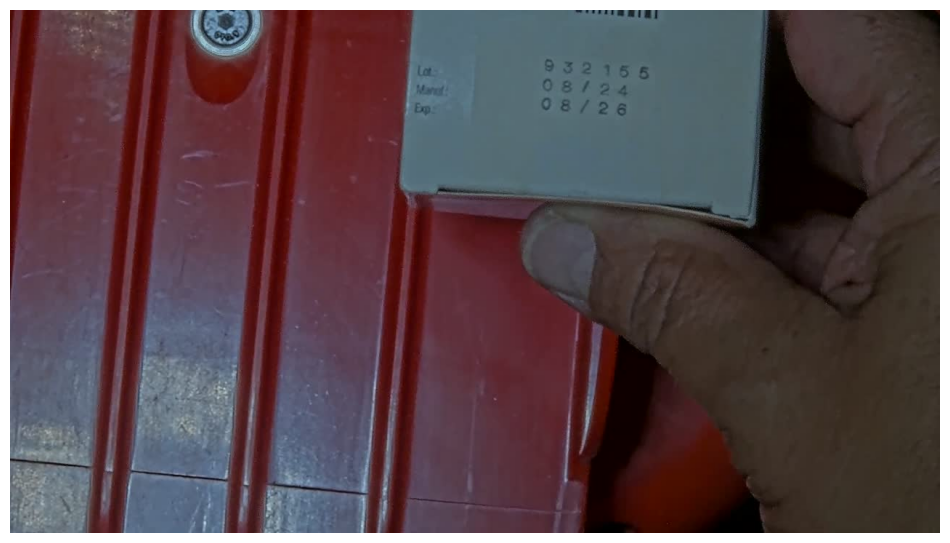

In [10]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

In [11]:
process_image(paddle_ocr, img)

Texto OCR:
932155
Lot
Mandl
08/24
Exp
08/26


{'lote': '932155',
 'fecha_fabricacion': '2024-08',
 'fecha_caducidad': '2026-08'}

In [ ]:
# Detecta todas la información de las imágenes:

# 1- Sí
# 2- No
# 3- Sí
# 4- Sí
# 5- Sí (Confunde D con 0)
# 6- Sí
# 7- Sí
# 8- Sí
# 9- 
# 10- 
# 11- 
# 12- 
# 13- 
# 14- 
# 15- 

### Vamos a probar con otro OCR

In [5]:
#pip install pytesseract


In [2]:
import pytesseract
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

In [6]:
# Problemas:

# 1a0b72b0 - Junta dos líneas de texto
# 1a3b95bb
# 1aaa2407 - Lote: en Lote1 y vcto: en uct01. Los dos puntos los convierte en un 1
# 1b4df212 - Está rotada y no entiende bien el número de lote
# 2b733ecd - Junta dos líneas de texto
# 2c9787d9 - "Lote N° :"
# 4d95d836 - LOTE:, y FP Y FE

# ¿Cómo lidiar con rotadas? use_angle_cls=True
# Junta dos cadenas de texto (arriba y abajo en una)
# Convierte dos puntos en "1"

In [3]:
path_img = Path("pruebas14082026/1a0b72b0")
img = cv2.imread(str(path_img / "original.png"))

Texto reconocido:
Ht at ohildren : ‘
i Novartia Aloaciences Pani 8A | ; " .
| lian ana N° 154, Oficina 604 : 7
i laid, Lima « Perd | :
HUG 201001 p00R~ j : ee
AON" CEOS47a 4 a oy
. MFO: | :
Manutactured by O41 2024 : ;
Delphe SAS 4 & ee: d a
eh Buningus SAS, EXP: Ae ee kee,
Novartis Pharma AG q i
Basle, Switzerland LOT: | 4 :



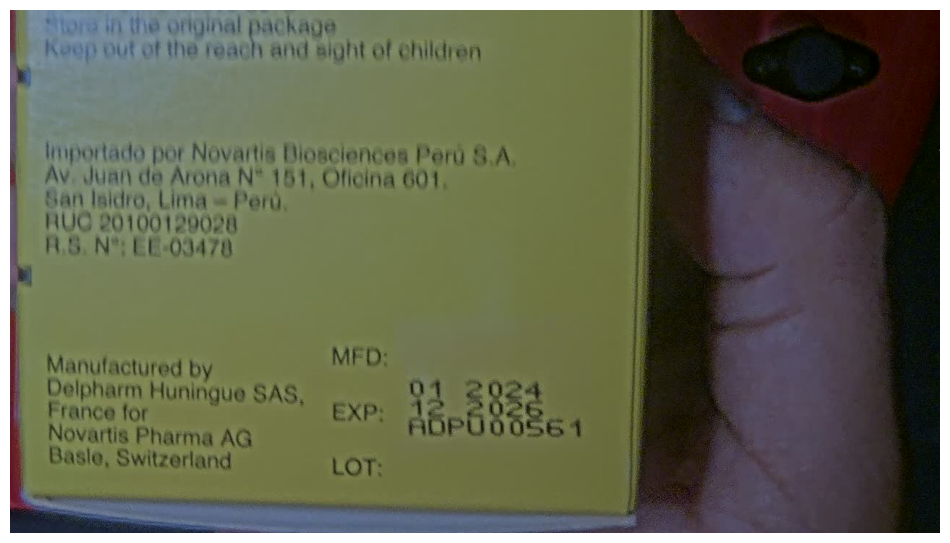

In [4]:

# Convertir a escala de grises
#gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Mejorar el contraste mediante binarización
# processed = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

# Ejecutar OCR
config = "--psm 6"
text = pytesseract.image_to_string(img, config=config)

# Mostrar el texto reconocido en el terminal
print("Texto reconocido:")
print(text)

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

Detecta muy mal

### Let's try with different filters

In [ ]:
# GRIS

gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
imagen_limpia = clahe.apply(gris)
cv2.imwrite("salida/gris.png", imagen_limpia)

imagen_3c = cv2.cvtColor(imagen_limpia, cv2.COLOR_GRAY2BGR) # Necesitas tres canales ya que Paddle OCR lo requiere

for res in paddle_ocr.predict(imagen_3c):
    res.print()
    res.save_to_img("salida")        # imagen con las cajas dibujadas
    res.save_to_json("salida") 

True

In [ ]:
# CLAHE

lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
l, a, b = cv2.split(lab)
l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)

imagen_3c = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

cv2.imwrite("salida/clahe.png", imagen_3c)

for res in paddle_ocr.predict(imagen_3c):
    res.print()
    res.save_to_img("salida")        
    res.save_to_json("salida") 

In [ ]:
# ADAPTATIVE

gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
bw = cv2.adaptiveThreshold(gris, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY, 31, 15)

imagen_3c = cv2.cvtColor(bw, cv2.COLOR_GRAY2BGR) 

cv2.imwrite("salida/adaptative.png", imagen_3c)

for res in paddle_ocr.predict(imagen_3c):
    res.print()
    res.save_to_img("salida")        
    res.save_to_json("salida") 


In [ ]:

def brillo_contraste(img, alpha=1.3, beta=20):
    # alpha: contraste (1.0 = igual), beta: brillo (-100..100)
    return cv2.convertScaleAbs(img, alpha=alpha, beta=beta)


def gamma(img, g=0.6):
    # g < 1 aclara, g > 1 oscurece
    tabla = np.array([(i / 255.0) ** g * 255 for i in range(256)]).astype("uint8")
    return cv2.LUT(img, tabla)



def normalizar(img):
    return cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)
